### CUSTOMER CHURN PREDICTION 

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

#Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

#MODELS
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

#Metrics & utilities
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

#Display settings
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
pd.set_option('display.max_columns', 200)



### Step 2. Load the data

In [ ]:
#Load dataset (adjust path if needed)
df = pd.read_csv(r"C:\Users\Dell\Downloads\Bank Customer Churn Prediction.csv")
print("Shape:", df.shape)
df.head()

Shape: (10000, 12)


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


### step 3. Initial inspection of the dataset

In [ ]:
#Info and summary of the dataset
display(df.info())
display(df.describe(include='all').T)

#Missing values
print("\nMissing values per column:")
print(df.isnull().sum())

#Target variable distribution
print("\nChurn value counts:")
print(df['churn'].value_counts(normalize=False))
print("\nChurn value proportions:")
print(df['churn'].value_counts(normalize=True))

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  str    
 3   gender            10000 non-null  str    
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), str(2)
memory usage: 1.0 MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
credit_score,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
country,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
products_number,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0
credit_card,10000.0,NaN,NaN,NaN,0.7055,0.45584,0.0,0.0,1.0,1.0,1.0
active_member,10000.0,NaN,NaN,NaN,0.5151,0.499797,0.0,0.0,1.0,1.0,1.0



Missing values per column:
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Churn value counts:
churn
0    7963
1    2037
Name: count, dtype: int64

Churn value proportions:
churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64


### Step 4. Exploratory Data Analysis (EDA)--visualization 

We'll look at the distribution of numerical features and the relationship between categorical features and the target variable (churn).

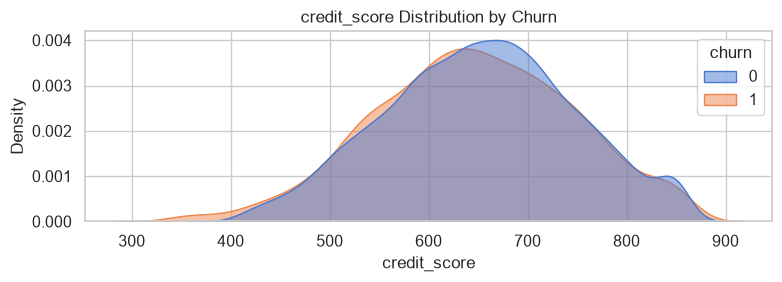

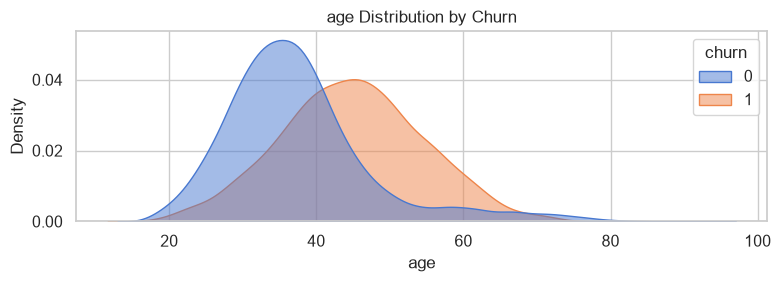

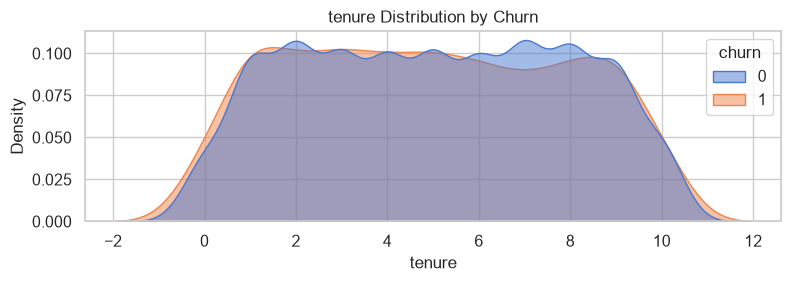

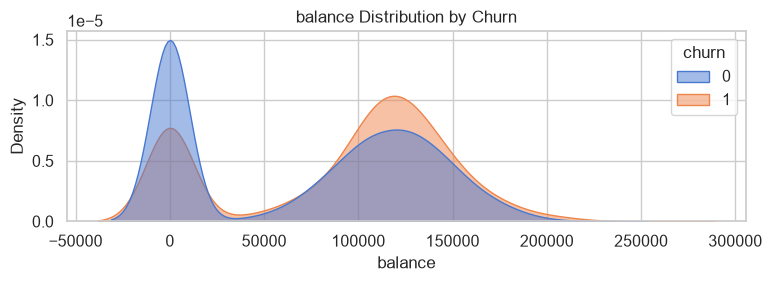

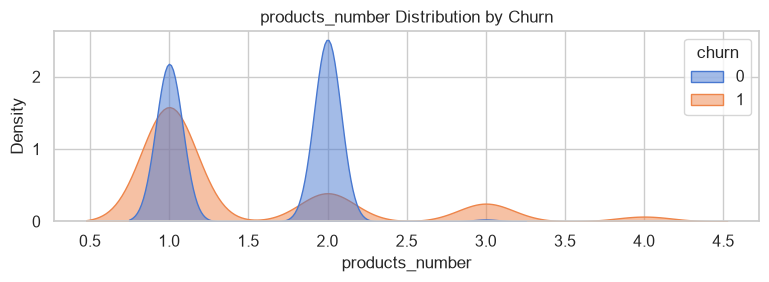

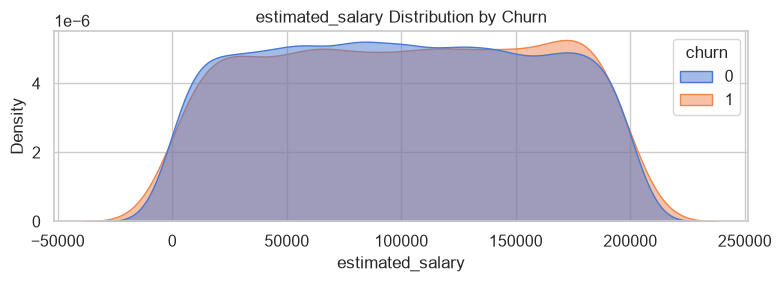

In [ ]:
num_cols = ['credit_score', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary']

#---Distribution plots
for col in num_cols:
    plt.figure(figsize=(8,3))
    sns.kdeplot(data=df, x=col, hue='churn', fill=True, common_norm=False, alpha=0.5)
    plt.title(f'{col} Distribution by Churn')
    plt.tight_layout()
    plt.show()

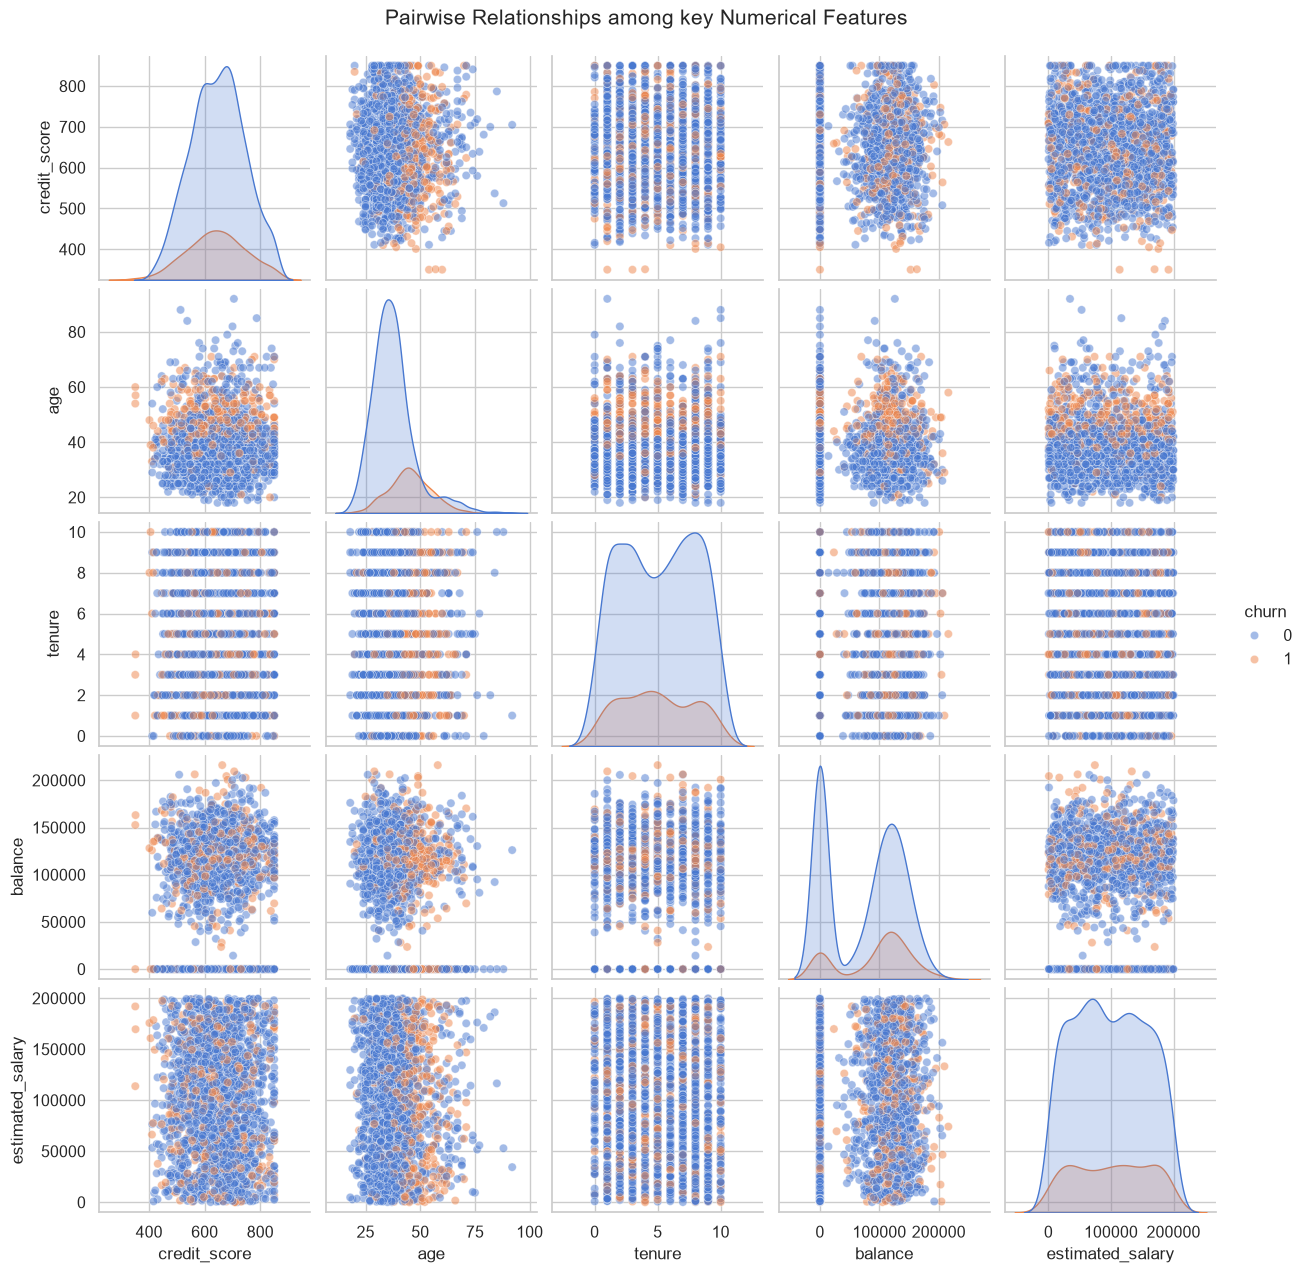

In [ ]:
### ---pairplot(sampled for speed)
sns.pairplot(df.sample(frac=0.2, random_state=42), vars= ['credit_score', 'age', 'tenure', 'balance', 'estimated_salary'], hue='churn', diag_kind='kde', palette='muted', plot_kws={'alpha':0.5})
plt.suptitle('Pairwise Relationships among key Numerical Features', y=1.02)
plt.show()

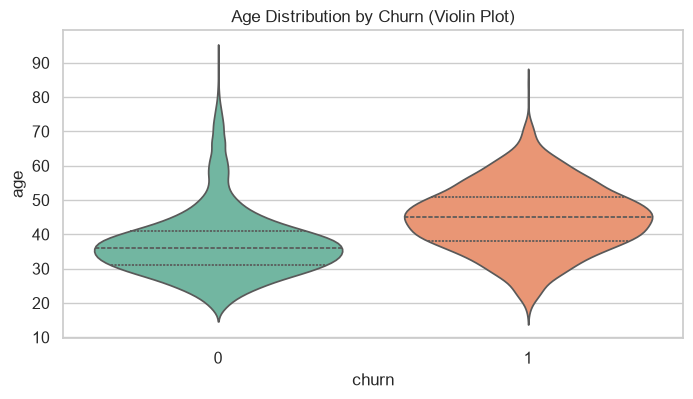

In [ ]:
# ------------ Violin plot for Age
plt.figure(figsize=(8,4))
sns.violinplot(data=df, x='churn', y='age', inner='quart', palette='Set2')
plt.title('Age Distribution by Churn (Violin Plot)')
plt.show()


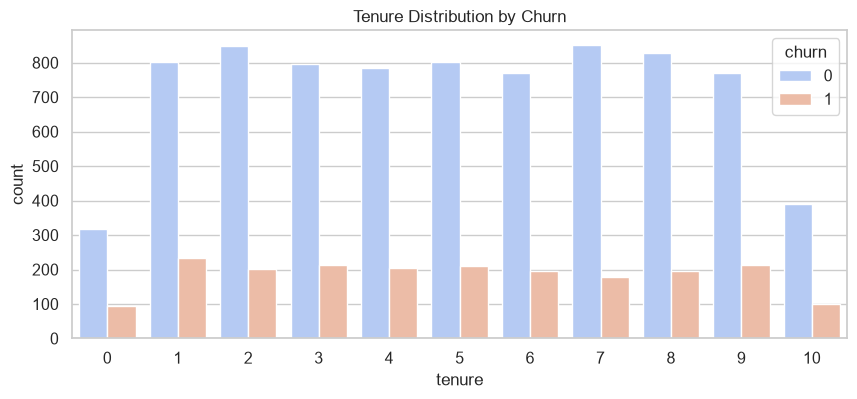

In [ ]:
#------tenure distribution by churn
plt.figure(figsize=(10,4))
sns.countplot(data=df, x='tenure', hue='churn', palette='coolwarm')
plt.title('Tenure Distribution by Churn')
plt.show()

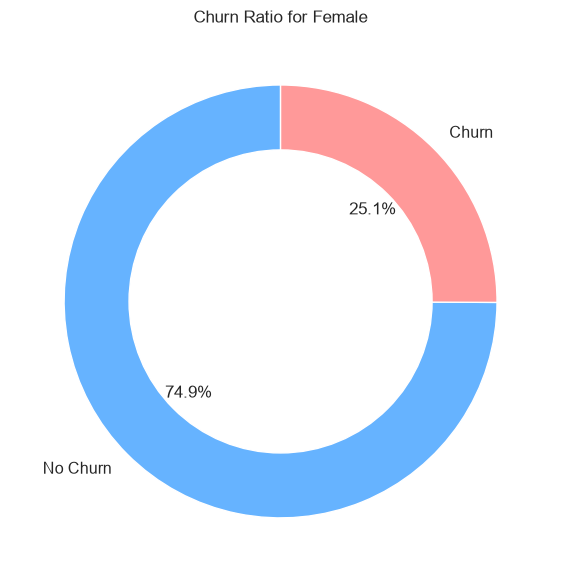

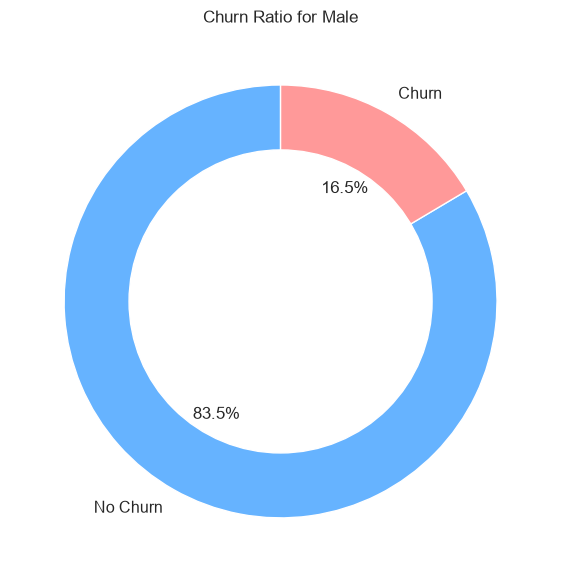

In [ ]:
#------Gender vs Churn donut chart
gender_counts = df.groupby('gender')['churn'].value_counts(normalize=True).unstack().fillna(0)
for gender in gender_counts.index:
    plt.figure(figsize=(6,6))
    plt.pie(gender_counts.loc[gender], labels=['No Churn', 'Churn'], autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999'])
    center=plt.Circle((0,0), 0.70, fc='white')
    fig = plt.gcf()
    fig.gca().add_artist(center)
    plt.title(f'Churn Ratio for {gender}')
    plt.tight_layout()
    plt.show()

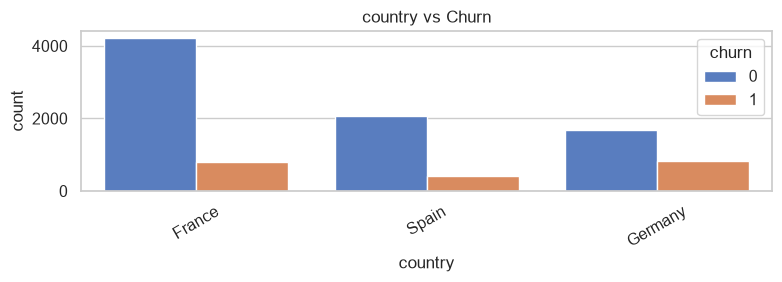

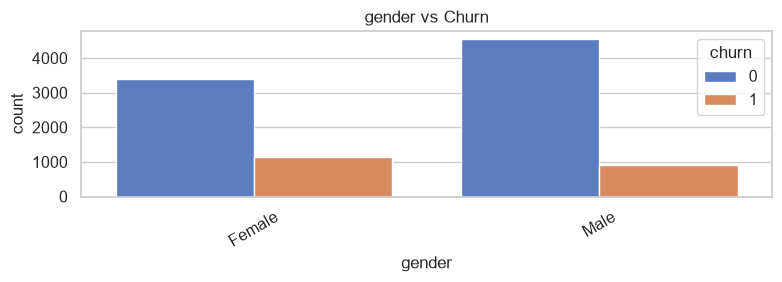

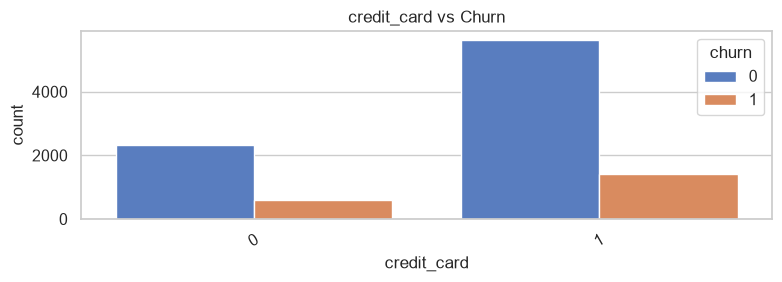

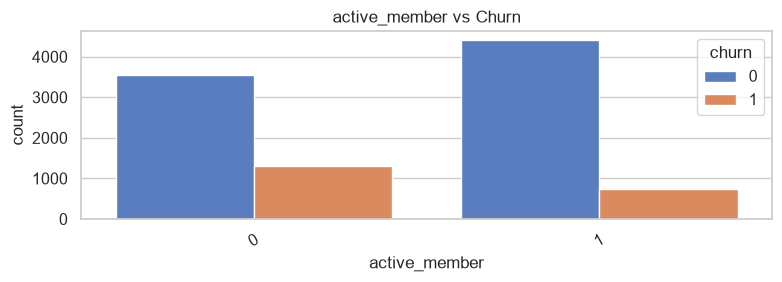

In [ ]:
#-------------Categorical features
cat_cols = ['country', 'gender', 'credit_card', 'active_member']
for c in cat_cols:
    plt.figure(figsize=(8,3))
    sns.countplot(data=df, x=c, hue='churn')
    plt.title(f'{c} vs Churn')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
    

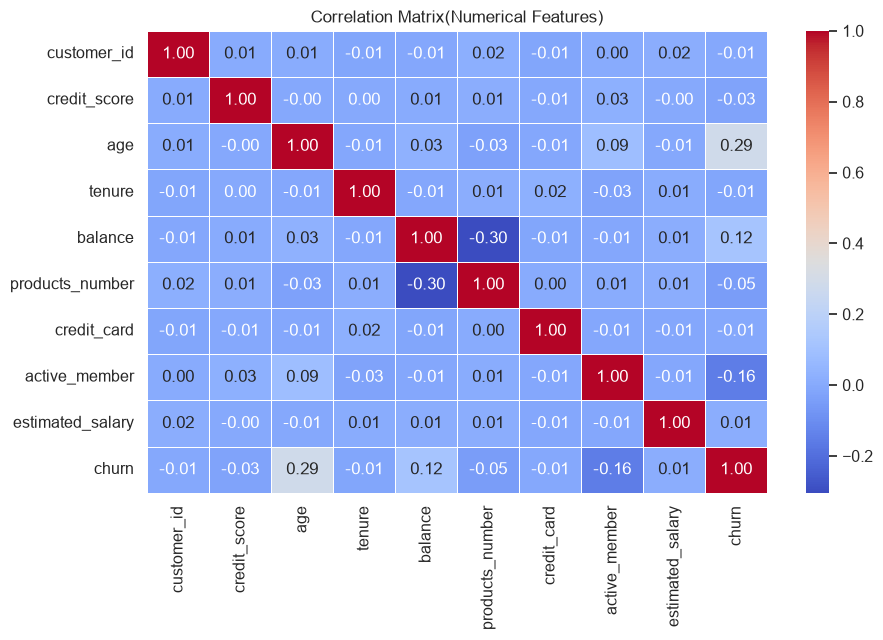

In [ ]:
import pandas as pd

# pandas is already imported in the notebook.

###-----------Heatmap visualization of correlations among numerical features
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
if 'df' not in globals():
    df = pd.read_csv(r"C:\Users\Dell\Downloads\Bank Customer Churn Prediction.csv")

numeric_df = df.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Matrix(Numerical Features)')
plt.show()

In [ ]:
#---Numeric correlation heatmap
numeric_data = df[num_cols]#use the numeric columns from your feature-engineered dataframe
corr = numeric_data.corr()
corr.style.background_gradient(cmap='coolwarm')

,credit_score,age,tenure,balance,products_number,estimated_salary
credit_score,1.000000,-0.003965,0.000842,0.006268,0.012238,-0.001384
age,-0.003965,1.000000,-0.009997,0.028308,-0.030680,-0.007201
tenure,0.000842,-0.009997,1.000000,-0.012254,0.013444,0.007784
balance,0.006268,0.028308,-0.012254,1.000000,-0.304180,0.012797
products_number,0.012238,-0.030680,0.013444,-0.304180,1.000000,0.014204
estimated_salary,-0.001384,-0.007201,0.007784,0.012797,0.014204,1.000000


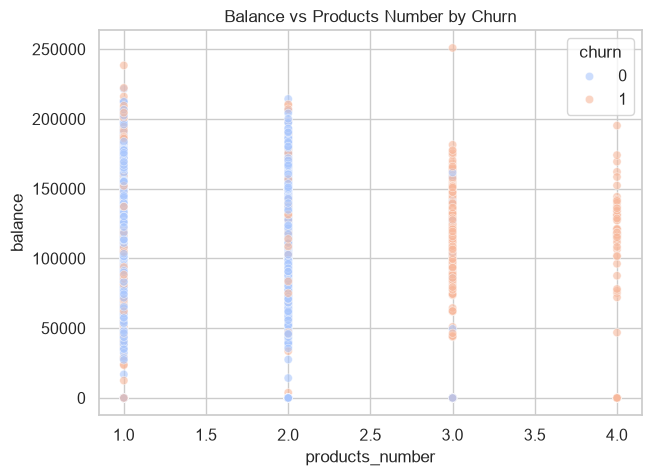

In [ ]:
#----Balance vs Products scatter
plt.figure(figsize=(7,5))
sns.scatterplot(data=df, x='products_number', y='balance', hue='churn', alpha=0.6, palette='coolwarm')
plt.title('Balance vs Products Number by Churn')
plt.show()

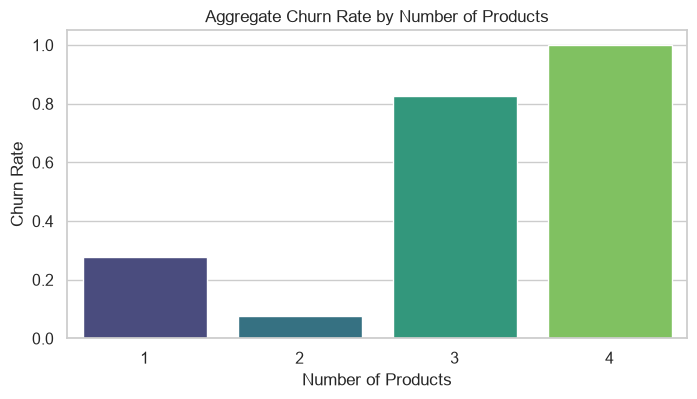

In [ ]:
#----Aggregate churn rate per number of products
churn_rate = df.groupby('products_number')['churn'].mean().reset_index()
plt.figure(figsize=(8,4))
sns.barplot(data=churn_rate, x='products_number', y='churn', palette='viridis')
plt.title('Aggregate Churn Rate by Number of Products')
plt.xlabel('Number of Products')
plt.ylabel('Churn Rate')
plt.show()

# Step 5. Feature Engineering and Preprocessing
create meaningful features from the existing dataset to enhance model performance. This may include creating new variables, transforming existing ones, and handling categorical variables appropriately.

In [ ]:
#Feature Engineering examples 
df_fe = df.copy()
#balance per product
df_fe['balance_per_product'] = df_fe['balance'] / (df_fe['products_number'].replace(0, np.nan) + 1)# Adding 1 to avoid division by zero
df_fe['balance_per_product'].fillna(df_fe['balance'], inplace=True)  # Fill NaN values with balance where products_number was 0

#SAlary to balance ratio
df_fe['salary_balance_ratio'] = df_fe['estimated_salary'] / (df_fe['balance'].replace(0, np.nan) + 1)  # Adding 1 to avoid division by zero
df_fe['salary_balance_ratio'].fillna(df_fe['estimated_salary'], inplace=True)

#Age groups
df_fe['age_group'] = pd.cut(df_fe['age'], bins=[0, 30, 40, 50, 60, np.inf], labels=['<30', '30-39', '40-49', '50-59', '60+'])

#tenure buckets
df_fe['tenure_bucket'] = pd.cut(df_fe['tenure'], bins=[-1, 2, 4, 6, 8, 10], labels=['0-1', '2-3', '4-5', '6-7', '8-10'])

#flag for high balance
df_fe['high_balance_flag'] = (df_fe['balance'] > df_fe['balance'].median()).astype(int)

#quick check of the new features
df_fe[['balance_per_product', 'salary_balance_ratio', 'age_group', 'tenure_bucket', 'high_balance_flag']].head()

,balance_per_product,salary_balance_ratio,age_group,tenure_bucket,high_balance_flag
0,0.00,NaN,40-49,0-1,0
1,41903.93,1.342848,40-49,0-1,0
2,39915.20,0.713581,40-49,6-7,1
3,0.00,NaN,30-39,0-1,0
4,62755.41,0.630093,40-49,0-1,1


# Step 6. Preprocessing - encoding & scaling

In [ ]:
#define features and target
target = 'churn'
drop_cols = ['customer_id', 'churn']  # Drop customer_id and target from features
features = [col for col in df_fe.columns if col not in drop_cols]

numeric_features = ['creditscore', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary', 'balance_per_product', 'salary_balance_ratio ']
categorical_features = ['country', 'gender', 'credit_card', 'active_member', 'age_group', 'tenure_bucket', 'high_balance_flag']

df_fe[categorical_features] = df_fe[categorical_features].astype('object')  # Convert categorical features to object type for encoding
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),  
    ('scaler', StandardScaler())])  
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),   
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

Numeric features: ['creditscore', 'age', 'tenure', 'balance', 'products_number', 'estimated_salary', 'balance_per_product', 'salary_balance_ratio ']
Categorical features: ['country', 'gender', 'credit_card', 'active_member', 'age_group', 'tenure_bucket', 'high_balance_flag']


# Step 7. Train-test split

In [ ]:
X = df_fe[features]
y = df_fe[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train shape:', X_train.shape, 'Test shape:', X_test.shape)
print('Train churn distribution:\n', y_train.value_counts(normalize=True))
print('Test churn distribution:\n', y_test.value_counts(normalize=True))

Train shape: (8000, 15) Test shape: (2000, 15)
Train churn distribution:
 churn
0    0.79625
1    0.20375
Name: proportion, dtype: float64
Test churn distribution:
 churn
0    0.7965
1    0.2035
Name: proportion, dtype: float64


# Step 8. Train multiple models with a simple pipeline and evaluate their performance using cross-validation.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=500),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=200, random_state=42),
    'SVC': SVC(probability=True, random_state=42)
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
    numeric_features = [
        'credit_score', 'age', 'tenure', 'balance', 'products_number',
        'estimated_salary', 'balance_per_product', 'salary_balance_ratio'
    ]

    preprocessor = ColumnTransformer([
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    scores = cross_val_score(
        pipe, X_train, y_train,
        cv=cv, scoring='roc_auc', n_jobs=-1
    )
    results[name] = scores
    print(f"{name}: Mean ROC AUC: {scores.mean():.4f}, Std: {scores.std():.4f}")

Logistic Regression: Mean ROC AUC: 0.7834, Std: 0.0203
Random Forest: Mean ROC AUC: 0.8496, Std: 0.0135
Gradient Boosting: Mean ROC AUC: 0.8609, Std: 0.0117
AdaBoost: Mean ROC AUC: 0.8446, Std: 0.0137


# Boxplot of cv Auc scores

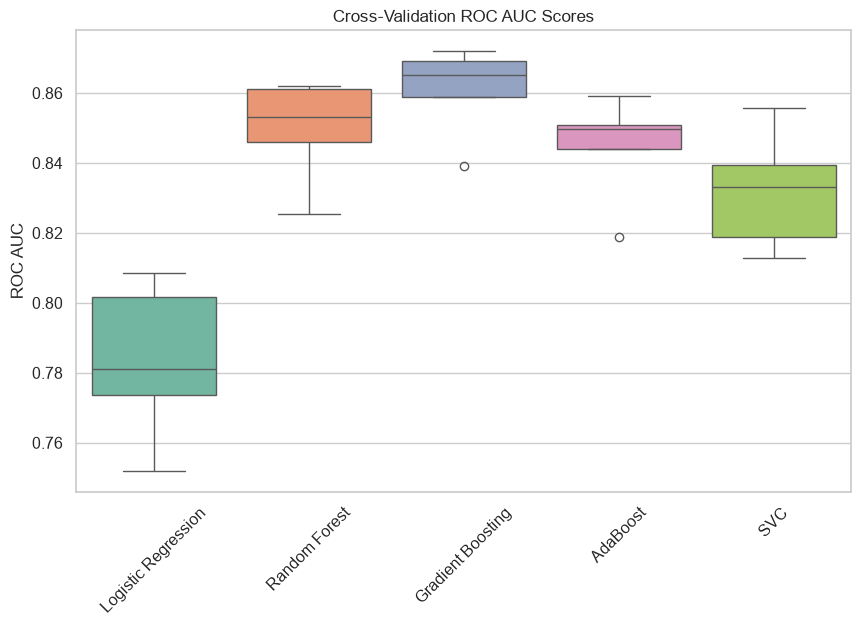

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=[results[m] for m in list(results.keys())], palette='Set2')
plt.xticks(ticks=range(len(results)), labels=list(results.keys()), rotation=45)
plt.ylabel('ROC AUC')
plt.title('Cross-Validation ROC AUC Scores')
plt.show()

# Step 9. Fit best model on full train set and evaluate on test set

In [ ]:
#choose the best model based on mean ROC AUC
best_name = max(results.keys(), key=lambda k: results[k].mean())
best_name, results[best_name].mean()

('Gradient Boosting', np.float64(0.860855139601853))